# Chapter 5 — Learning Multiple Weights at a Time: Generalizing Gradient Descent
### Reproduction & Theoretical Deep-Dive — *grokking Deep Learning* (Manning)

Chapter 4 learned **one** weight. Real networks have many inputs, many outputs and therefore many weights.
This chapter shows that nothing fundamentally new is needed: gradient descent generalises directly, one
weight at a time — and, written with vectors and matrices, all at once.

> **Note on the examples.** The numbers and the scenario are my own; the progression follows the chapter:
> multiple inputs → multiple outputs → multiple inputs *and* outputs, plus a look at what the weights actually do while learning.

**Roadmap**
1. Gradient descent with several inputs (derivation + implementation)
2. How each weight gets its share of the correction
3. Freezing one weight: weights are coupled
4. Several outputs
5. Several inputs and several outputs (weight matrix) + numerical gradient check
6. Training on a whole dataset and recovering the true weights

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs('outputs', exist_ok=True)
np.set_printoptions(precision=4, suppress=True)

## 1. Gradient descent with several inputs

**Predict.** With $n$ inputs and one weight per input,

$$\hat y = \sum_{i=1}^{n} w_i x_i = \mathbf{w}\cdot\mathbf{x}.$$

**Compare.** Same squared error as before, $E = (\hat y - y)^2$. Write $\delta = \hat y - y$ for the signed error.

**Learn.** We need the slope of $E$ with respect to *each* weight. Only the term $w_i x_i$ of the sum involves $w_i$, so
$\partial \hat y/\partial w_i = x_i$ and, by the chain rule,

$$\frac{\partial E}{\partial w_i} = 2\,\delta\,x_i
\qquad\Longleftrightarrow\qquad
\nabla_{\mathbf w}E = 2\,\delta\,\mathbf{x}.$$

The update is the same as before applied to every weight: $\mathbf{w}\leftarrow\mathbf{w}-\alpha\,2\delta\,\mathbf{x}$.

**Interpretation.** All weights see the *same* error $\delta$, but each gets a share proportional to **its own
input** $x_i$:
- a big input has a big influence on the prediction, so its weight is adjusted a lot;
- an input equal to 0 had no influence on this prediction, so its weight is **not** changed at all;
- a negative input flips the direction of the adjustment (to raise the output, a weight on a negative input must go down).

In [2]:
x = np.array([1.2, 0.5, 2.0])           # three inputs
target = 3.0
w_start = np.array([0.1, -0.2, 0.3])    # initial weights
alpha = 0.05

def train(x, target, w_start, alpha, n_iter, frozen=()):
    # gradient descent for a single-output linear model; 'frozen' lists weight indices that must not change
    w = w_start.copy()
    errs, ws = [], [w.copy()]
    for _ in range(n_iter):
        pred = x @ w
        delta = pred - target
        errs.append(delta ** 2)
        grad = 2 * delta * x
        for i in frozen:
            grad[i] = 0.0
        w = w - alpha * grad
        ws.append(w.copy())
    return w, np.array(errs), np.array(ws)

w_final, errs, ws_hist = train(x, target, w_start, alpha, n_iter=25)

print("iter | prediction |  error   |        weights")
for t in [0, 1, 2, 3, 4, 5, 10, 24]:
    print(f"{t:4d} | {ws_hist[t] @ x:10.4f} | {errs[t]:8.5f} | {ws_hist[t]}")

iter | prediction |  error   |        weights
   0 |     0.6200 |  5.66440 | [ 0.1 -0.2  0.3]
   1 |     1.9742 |  1.05222 | [ 0.3856 -0.081   0.776 ]
   2 |     2.5579 |  0.19546 | [ 0.5087 -0.0297  0.9812]
   3 |     2.8095 |  0.03631 | [ 0.5617 -0.0076  1.0696]
   4 |     2.9179 |  0.00674 | [0.5846 0.0019 1.1077]
   5 |     2.9646 |  0.00125 | [0.5945 0.006  1.1241]
  10 |     2.9995 |  0.00000 | [0.6018 0.0091 1.1364]
  24 |     3.0000 |  0.00000 | [0.6019 0.0091 1.1366]


**Reading the output.** The prediction climbs to 3 and the error melts away, although *three* numbers were being
adjusted at once. For this linear model one can show the signed error shrinks by the same factor every step:
$\delta_{t+1}=\bigl(1-2\alpha\,\lVert\mathbf{x}\rVert^2\bigr)\delta_t$ (the multi-input version of Chapter 4's $c$).
Let me check that, and also check the "zero input → zero update" claim.

In [3]:
c = 1 - 2 * alpha * np.sum(x ** 2)
deltas = np.array([ws_hist[t] @ x - target for t in range(6)])
print(f"predicted factor c = {c:.4f}")
print("measured delta ratios:", deltas[1:] / deltas[:-1])

x_zero = np.array([1.2, 0.0, 2.0])      # the middle input is 0
delta0 = w_start @ x_zero - target
print("gradient when middle input is 0:", 2 * delta0 * x_zero, " -> middle weight gets no update")

predicted factor c = 0.4310
measured delta ratios: [0.431 0.431 0.431 0.431 0.431]
gradient when middle input is 0: [-5.472 -0.    -9.12 ]  -> middle weight gets no update


## 2. What does learning converge to?

With **one** example and three weights, the equation $\mathbf{w}\cdot\mathbf{x}=y$ describes a whole *plane* of perfect solutions:
infinitely many weight vectors give zero error. Every gradient step moves the weights **along $\mathbf{x}$**, so gradient descent
ends at the solution closest to where it started:

$$\mathbf{w}_\infty=\mathbf{w}_0+\mathbf{x}\,\frac{y-\mathbf{w}_0\cdot\mathbf{x}}{\mathbf{x}\cdot\mathbf{x}}.$$

This is a useful warning: **a single example cannot reveal which weights are "right"** — the result depends on the starting point.

In [4]:
w_formula = w_start + x * (target - w_start @ x) / (x @ x)
w_long, _, _ = train(x, target, w_start, alpha, n_iter=500)
print("gradient descent result :", w_long)
print("projection formula      :", w_formula)
print("match?                  :", np.allclose(w_long, w_formula, atol=1e-6))

gradient descent result : [0.6019 0.0091 1.1366]
projection formula      : [0.6019 0.0091 1.1366]
match?                  : True


## 3. Freezing a weight

What if one weight is **not allowed to learn** (a "frozen" weight)? If the weights were independent, the error could not
reach zero any more. Let us freeze weight 0 and see.

all weights learning : [0.6019 0.0091 1.1366]   final error: 1.97e-31
weight 0 frozen      : [0.1  0.08 1.42]   final error: 2.42e-28


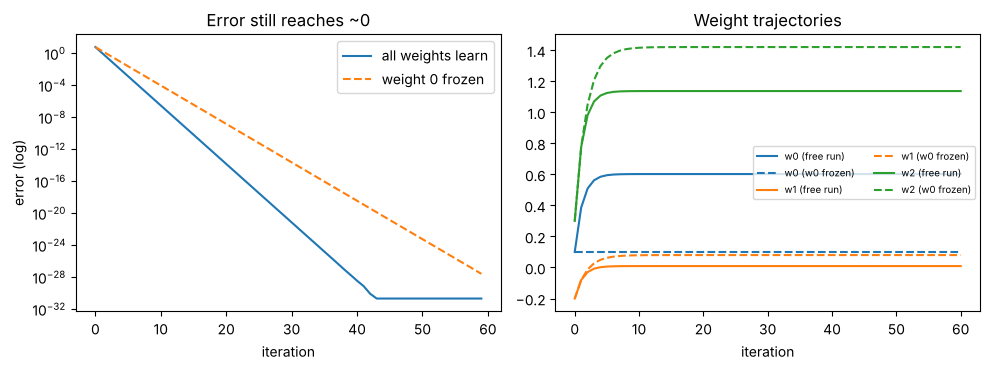

In [5]:
w_free, err_free, hist_free = train(x, target, w_start, alpha, n_iter=60)
w_frozen, err_frozen, hist_frozen = train(x, target, w_start, alpha, n_iter=60, frozen=(0,))

print("all weights learning :", w_free,   "  final error:", f"{err_free[-1]:.2e}")
print("weight 0 frozen      :", w_frozen, "  final error:", f"{err_frozen[-1]:.2e}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].semilogy(err_free, label='all weights learn')
axes[0].semilogy(err_frozen, label='weight 0 frozen', ls='--')
axes[0].set_xlabel('iteration'); axes[0].set_ylabel('error (log)'); axes[0].legend(); axes[0].set_title('Error still reaches ~0')
colors = ['tab:blue', 'tab:orange', 'tab:green']
for i in range(3):
    axes[1].plot(hist_free[:, i], color=colors[i], label=f'w{i} (free run)')
    axes[1].plot(hist_frozen[:, i], color=colors[i], ls='--', label=f'w{i} (w0 frozen)')
axes[1].set_xlabel('iteration'); axes[1].set_title('Weight trajectories'); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig('outputs/freezing_a_weight.png', dpi=110)
plt.show()

**Reading the output.** The error still goes to ≈ 0 even with weight 0 frozen, because the *other* weights
compensate — but they end up with different values than in the free run (dashed vs solid lines). The weights are **coupled**: each
one's best value depends on the others, and a network can reach the same predictions with different weight settings.

## 4. Gradient descent with several outputs

Now one input vector feeds $m$ outputs, each with its **own weight vector** (a row of a matrix $W$) and its **own target**:

$$\hat y_j=\sum_i W_{ji}x_i,\qquad \delta_j=\hat y_j-y_j,\qquad E=\sum_{j=1}^{m}\delta_j^2 .$$

Weight $W_{ji}$ only affects output $j$, so $\partial E/\partial W_{ji}=2\,\delta_j\,x_i$. In matrix form the
gradient is the **outer product** of the error vector and the input vector:

$$\nabla_W E = 2\,\boldsymbol{\delta}\,\mathbf{x}^{\top}\qquad(\text{shape } m\times n,\ \text{same as } W).$$

Each output learns *independently* of the others — it is just several copies of Section 1 side by side.
This also covers the general case of several inputs **and** several outputs.

In [6]:
def total_error(W, x, target):
    return np.sum((W @ x - target) ** 2)

def analytic_grad(W, x, target):
    delta = W @ x - target                   # shape (n_out,)
    return 2 * np.outer(delta, x)            # shape (n_out, n_in)

def numerical_grad(W, x, target, h=1e-6):
    g = np.zeros_like(W)
    for j in range(W.shape[0]):
        for i in range(W.shape[1]):
            Wp, Wm = W.copy(), W.copy()
            Wp[j, i] += h
            Wm[j, i] -= h
            g[j, i] = (total_error(Wp, x, target) - total_error(Wm, x, target)) / (2 * h)
    return g

rng = np.random.default_rng(1)
W0 = rng.normal(0, 0.3, size=(3, 3))
targets = np.array([3.0, 1.0, -0.5])

print("analytic gradient:\n", analytic_grad(W0, x, targets))
print("numerical gradient:\n", numerical_grad(W0, x, targets))
print("they agree:", np.allclose(analytic_grad(W0, x, targets), numerical_grad(W0, x, targets), atol=1e-5))

analytic gradient:
 [[ -6.1298  -2.5541 -10.2163]
 [ -2.5572  -1.0655  -4.262 ]
 [  1.4703   0.6126   2.4504]]
numerical gradient:
 [[ -6.1298  -2.5541 -10.2163]
 [ -2.5572  -1.0655  -4.262 ]
 [  1.4703   0.6126   2.4504]]
they agree: True


final predictions: [ 3.   1.  -0.5]  targets: [ 3.   1.  -0.5]


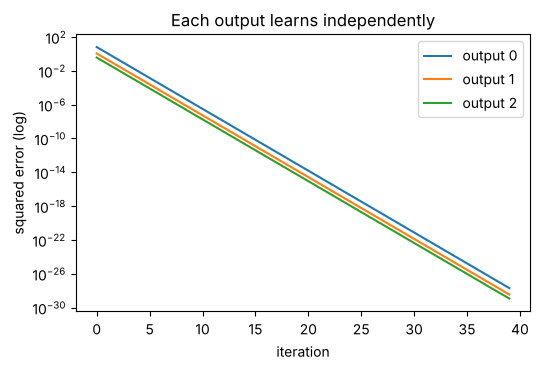

In [7]:
W = W0.copy()
alpha = 0.05
per_output_err = []
for _ in range(40):
    per_output_err.append((W @ x - targets) ** 2)
    W -= alpha * analytic_grad(W, x, targets)
per_output_err = np.array(per_output_err)

print("final predictions:", W @ x, " targets:", targets)

plt.figure(figsize=(5.5, 3.8))
for j in range(3):
    plt.semilogy(per_output_err[:, j], label=f'output {j}')
plt.xlabel('iteration'); plt.ylabel('squared error (log)'); plt.legend()
plt.title('Each output learns independently')
plt.tight_layout()
plt.savefig('outputs/multi_output_learning.png', dpi=110)
plt.show()

**Reading the output.** The analytic gradient, built from a single `np.outer`, matches the brute-force numerical gradient
entry for entry — so the formula is correct. All three outputs hit their targets, each following its own geometric decay.

## 5. A whole dataset: can the network recover the true weights?

So far we used one training example. With many examples, the weights become **identifiable**: they are pinned down by the data.
To test this, I invent a "true" weight matrix, generate data from it (plus a little noise), then let gradient descent
discover the weights from the data alone.

With $N$ examples stored as rows of $X$ ($N\times n$) and targets $Y$ ($N\times m$), the average-error gradient is

$$\nabla_W E = \frac{2}{N}\,(\hat Y-Y)^{\top}X,\qquad \hat Y = X W^{\top}.$$

In [8]:
rng = np.random.default_rng(7)
N = 200
W_true = np.array([[ 2.0, -1.0,  0.5],
                   [ 0.0,  1.5, -2.0]])           # 2 outputs, 3 inputs

X = rng.normal(size=(N, 3))
Y = X @ W_true.T + rng.normal(0, 0.1, size=(N, 2))   # data generated from W_true + noise

W = np.zeros((2, 3))                                 # start knowing nothing
alpha = 0.1
mse_history = []
for step in range(150):
    P = X @ W.T
    D = P - Y
    mse_history.append(np.mean(D ** 2))
    W -= alpha * (2 / N) * D.T @ X

print("true weights:\n", W_true)
print("learned weights:\n", W)
print("final MSE:", mse_history[-1], " (noise variance is 0.01)")

true weights:
 [[ 2.  -1.   0.5]
 [ 0.   1.5 -2. ]]
learned weights:
 [[ 2.0007 -1.0058  0.4851]
 [-0.0024  1.503  -2.0058]]
final MSE: 0.009176778652938106  (noise variance is 0.01)


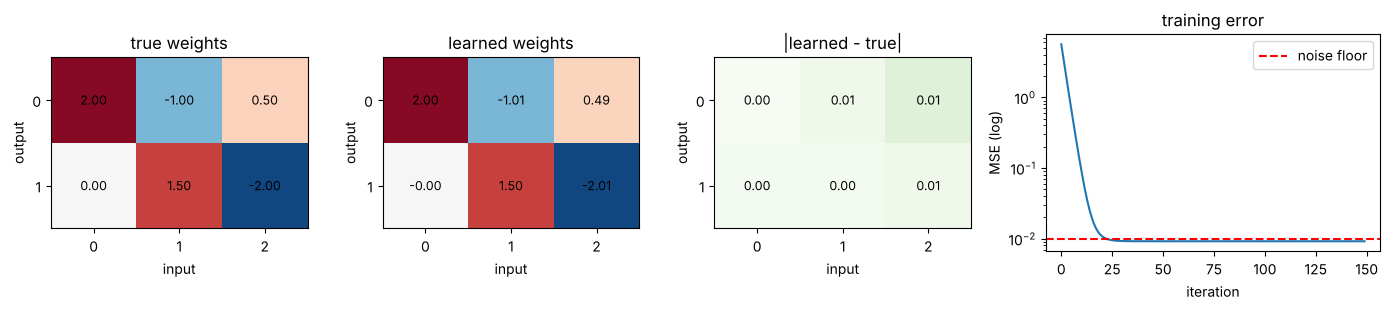

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2), gridspec_kw={'width_ratios': [1, 1, 1, 1.3]})
for ax, mat, title in zip(axes[:3], [W_true, W, np.abs(W - W_true)], ['true weights', 'learned weights', '|learned - true|']):
    im = ax.imshow(mat, cmap='RdBu_r' if title != '|learned - true|' else 'Greens', vmin=-2.2 if title != '|learned - true|' else 0,
                   vmax=2.2 if title != '|learned - true|' else 0.1)
    for (j, i), v in np.ndenumerate(mat):
        ax.text(i, j, f'{v:.2f}', ha='center', va='center', fontsize=9)
    ax.set_title(title); ax.set_xticks(range(3)); ax.set_yticks(range(2))
    ax.set_xlabel('input'); ax.set_ylabel('output')
axes[3].semilogy(mse_history)
axes[3].axhline(0.01, color='red', ls='--', label='noise floor')
axes[3].set_xlabel('iteration'); axes[3].set_ylabel('MSE (log)'); axes[3].legend(); axes[3].set_title('training error')
plt.tight_layout()
plt.savefig('outputs/recovering_true_weights.png', dpi=110)
plt.show()

**Reading the output.** Starting from all zeros, gradient descent finds weights within about 0.01–0.02 of the true ones, and the error
settles at the **noise floor** (variance 0.01): it cannot go lower because the noise in the data is unpredictable. This is what
"the network learned the pattern" means: the weights now encode the relationship hidden in the data.

## Summary

| Case | Prediction | Gradient |
|---|---|---|
| 1 input, 1 weight (Ch. 4) | $\hat y = xw$ | $2\delta x$ |
| several inputs, 1 output | $\hat y=\mathbf w\cdot\mathbf x$ | $2\delta\,\mathbf x$ |
| several outputs | $\hat{\mathbf y}=W\mathbf x$ | $2\,\boldsymbol\delta\,\mathbf x^{\top}$ (outer product) |
| dataset of $N$ examples | $\hat Y=XW^{\top}$ | $\tfrac{2}{N}(\hat Y-Y)^{\top}X$ |

Key takeaways
- Same rule as Chapter 4, applied to every weight: **error × input** says how much to change it.
- Weights on larger inputs change more; weights on zero inputs do not change.
- Weights are **coupled**; one example alone cannot determine them, while a dataset can.
- Always **check gradients numerically** when you derive a new formula.
- **Chapter 6** adds hidden layers, where the error signal for the hidden weights has to be *propagated backwards*.